In [1]:
import numpy as np
import matplotlib.pyplot as plt
from Shooting import shooting_test
from tqdm.notebook import tqdm
import time
from scipy.interpolate import CubicSpline
d= 3
lambdap = 0.2

## Testing the independence of the field profile on the coarseness of the datapoints and also the spline error

Also check the radius at which the function is zero-ed

  0%|          | 0/4 [00:00<?, ?it/s]

No zero-ing of the solution
phi_0 = 8.933 for h=0.010000
The spline error for h=0.010000 is 0.0
No zero-ing of the solution
phi_0 = 8.933 for h=0.005000
The spline error for h=0.005000 is 0.0
No zero-ing of the solution
phi_0 = 8.933 for h=0.002500
The spline error for h=0.002500 is 0.0
No zero-ing of the solution
phi_0 = 8.933 for h=0.001250
The spline error for h=0.001250 is 0.0


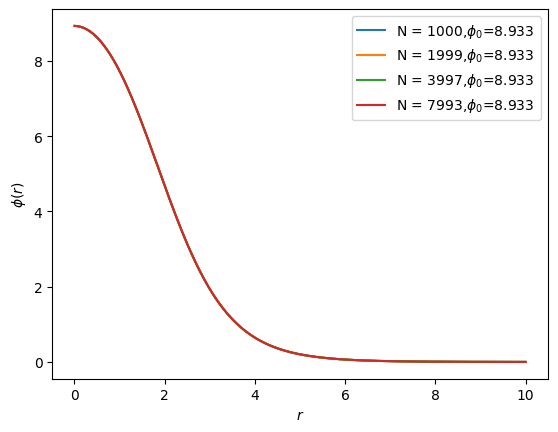

In [3]:
N = 1000
r_min =0.01
r_max = 10

bounce_vals = []
phi0_vals = []
r_eval0 = np.linspace(r_min, r_max, N)


for i in tqdm(range(4)):
    divider = 2**i
    n = divider * (N-1) + 1
    r_eval = np.linspace(r_min, r_max, n)
    h = r_eval[1] - r_eval[0]
    R, sol, phi_0, ind = shooting_test(d, lambdap, r_min, r_max, r_eval)
    if ind == n:
        print("No zero-ing of the solution")
    else:
        print(f"The zero-ing radial value is {R[ind]:.3f}")
    
    bounce_vals=sol[::divider]
    plt.plot(r_eval0, bounce_vals, label = fr'N = {n},$\phi_0$={phi_0:.3f} ')
    #simultaneously testing the spline error
    Phi = CubicSpline(R, sol)
    spl = np.max(np.abs(Phi(r_eval0) - sol[::divider])[r_eval0<0.5*r_max])
    print(f'phi_0 = {phi_0:.3f} for h={h:3f}')
    print(f'The spline error for h={h:3f} is {spl}')

plt.xlabel(r'$r$')
plt.ylabel(r'$\phi(r)$')
plt.legend()
plt.show()
    

    



## Test of the dependence of the shooting solution on the upper bound

  0%|          | 0/5 [00:00<?, ?it/s]

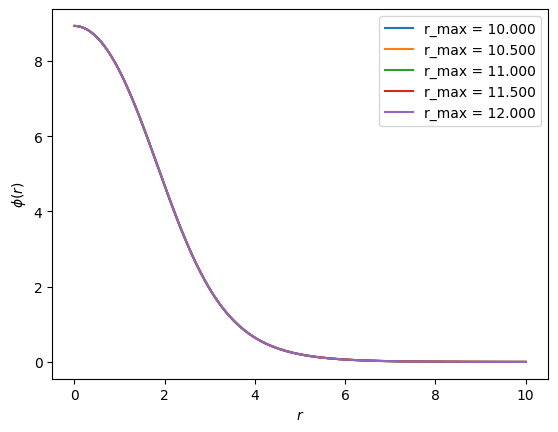

In [3]:
r_maxs = np.linspace(10, 12, 5)
plt.figure()
for i in tqdm(range(len(r_maxs))):
    r_m = r_maxs[i]
    r_eval = np.linspace(r_min, r_m, N)
    R, sol, phi_0, _ = shooting_test(d, lambdap, r_min, r_m, r_eval)
    plt.plot(r_eval0, CubicSpline(R, sol)(r_eval0), label = f"r_max = {r_m:.3f}")
plt.xlabel(r'$r$')
plt.ylabel(r'$\phi(r)$')
plt.legend()
plt.show()
    

  0%|          | 0/5 [00:00<?, ?it/s]

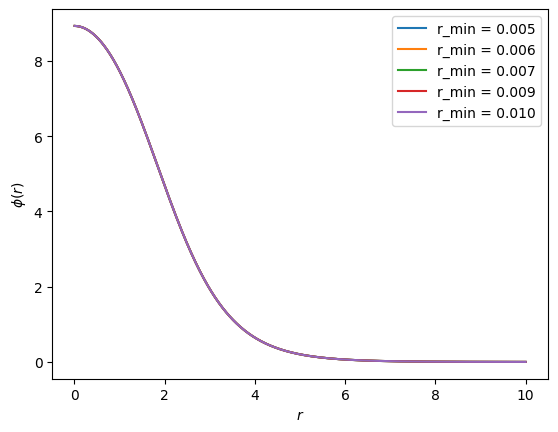

In [4]:
r_mins = np.linspace(0.005, 0.01, 5)
plt.figure()
for i in tqdm(range(len(r_mins))):
    r_m = r_mins[i]
    r_eval = np.linspace(r_m, r_max, N)
    R, sol, phi_0, _ = shooting_test(d, lambdap, r_m, r_max, r_eval)
    plt.plot(r_eval0, CubicSpline(R, sol)(r_eval0), label = f"r_min = {r_m:.3f}")
plt.xlabel(r'$r$')
plt.ylabel(r'$\phi(r)$')
plt.legend()
plt.show()


## Test of the bounce solution convergence vs the tolerance set in the bisection element

In [7]:
tols = np.linspace(1e-12, 1e-8, 5)
r_values = [100,250,500,750]
phi_vals = []
for i in tqdm(range(5)):
    tolerance = tols[i]
    R, sol, phi_0, _ = shooting_test(d, lambdap, r_min, r_max, r_eval0, tolerance = tolerance)
    phi_vals = (sol[r_values])
    print(f"The values for the bounce at r = {r_eval0[r_values]} are {phi_vals} for tolerance = {tolerance}")


  0%|          | 0/5 [00:00<?, ?it/s]

The values for the bounce at r = [1.01 2.51 5.01 7.51] are [7.71859201 3.11767569 0.1999477  0.01115719] for tolerance = 1e-12
The values for the bounce at r = [1.01 2.51 5.01 7.51] are [7.71859201 3.11767569 0.1999477  0.01115719] for tolerance = 2.50075e-09
The values for the bounce at r = [1.01 2.51 5.01 7.51] are [7.71859201 3.11767569 0.1999477  0.01115719] for tolerance = 5.000500000000001e-09
The values for the bounce at r = [1.01 2.51 5.01 7.51] are [7.71859201 3.11767569 0.1999477  0.01115719] for tolerance = 7.50025e-09
The values for the bounce at r = [1.01 2.51 5.01 7.51] are [7.71859201 3.11767569 0.1999477  0.0111572 ] for tolerance = 1e-08
